# Aula 02 · Aprendizagem e retropropagação

Vamos calcular a previsão da rede 2–2–1, medir a perda e descobrir como cada peso e viés influencia essa perda. Usaremos NumPy para acompanhar as contas e TensorFlow/Keras para conferir os gradientes e realizar um passo de SGD.

Execute as seções em ordem com o kernel da pasta `codigos`. O exemplo usa dados definidos no notebook e pode rodar na CPU.

## 01 · Propagação direta, logit e perda

A entrada é $x_1=1$ e $x_2=2$. O alvo é $y=1$. A rede tem **9 parâmetros**: quatro pesos e dois vieses na camada oculta e dois pesos e um viés na saída.

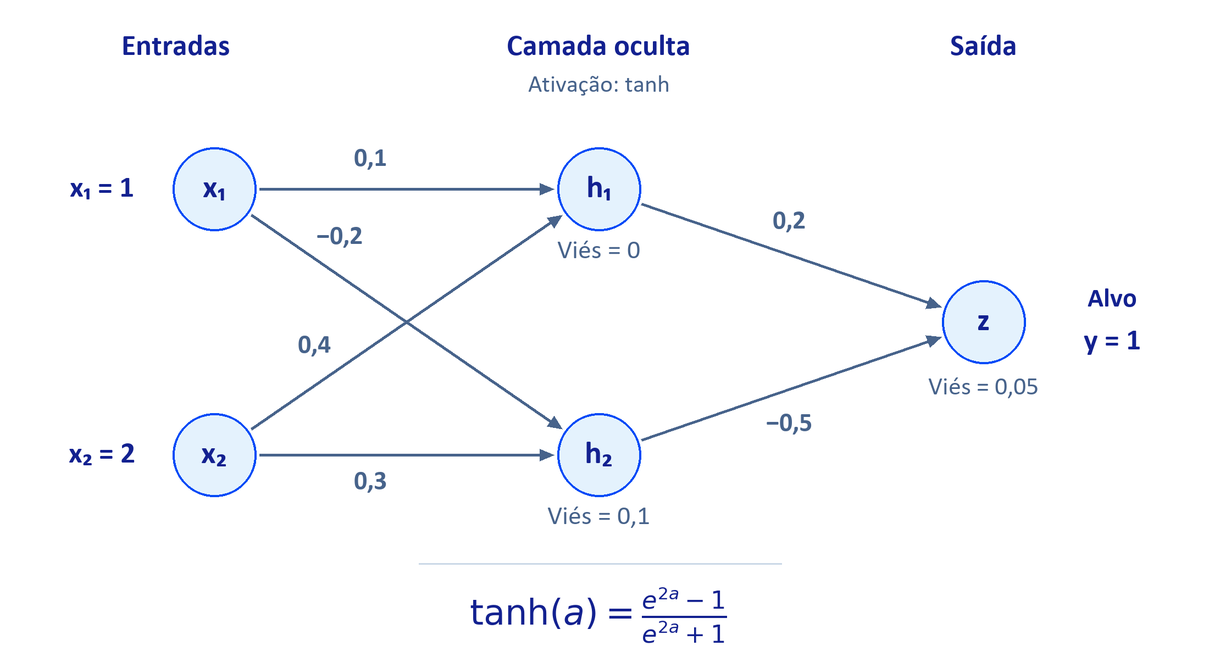

### Dicionário de símbolos

Em $w_{ij}$, o primeiro índice indica a entrada e o segundo indica o neurônio oculto.

| Símbolo | Como ler no exemplo |
|---|---|
| $x_i$ | Valor de entrada $i$ |
| $w_{ij}$ | Peso que liga a entrada $i$ ao neurônio oculto $j$ |
| $a_j$ | Soma ponderada com viés, antes da tanh, no neurônio $j$ |
| $h_j$ | Ativação do neurônio oculto $j$, depois da tanh |
| $v_j$ | Peso que liga $h_j$ à saída |
| $z$ | Logit, o escore bruto da rede |
| $p$, $y$, $L$ | Probabilidade da classe 1, alvo conhecido e perda |

### As contas da primeira previsão

Na fórmula, $b_j$ é o viés do neurônio oculto $j$ e $b_{\mathrm{saída}}$ é o viés da saída.

$$
a_j=\sum_i x_iw_{ij}+b_j,\qquad h_j=\tanh(a_j),\qquad
z=v_1h_1+v_2h_2+b_{\mathrm{saída}}.
$$

$$
\tanh(a)=\frac{e^{2a}-1}{e^{2a}+1},\qquad
p=\sigma(z)=\frac{1}{1+e^{-z}}.
$$

A primeira soma é $1(0{,}1)+2(0{,}4)+0=0{,}9$. A segunda é $1(-0{,}2)+2(0{,}3)+0{,}1=0{,}5$. Após a tanh, obtemos $h_1\approx0{,}71630$ e $h_2\approx0{,}46212$.

In [ ]:
import numpy as np

X = np.array([[1.0, 2.0]], dtype=np.float64)
y = np.array([[1.0]], dtype=np.float64)



In [ ]:
# Uma linha por origem e uma coluna por destino em cada matriz de pesos.
W1 = np.array([[0.1, -0.2], [0.4, 0.3]], dtype=np.float64)
b1 = np.array([0.0, 0.1], dtype=np.float64)
W2 = np.array([[0.2], [-0.5]], dtype=np.float64)
b2 = np.array([0.05], dtype=np.float64)
parametros = (W1, b1, W2, b2)
nomes_parametros = ("W1", "b1", "W2", "b2")

np.set_printoptions(precision=8, suppress=True)

In [ ]:
def propagacao_numpy(entradas, parametros_rede):
    pesos_oculta, vies_oculta, pesos_saida, vies_saida = parametros_rede

    # Cada linha de A1 e H corresponde a uma observação.
    A1 = entradas @ pesos_oculta + vies_oculta
    H = np.tanh(A1)
    z = H @ pesos_saida + vies_saida

    # sigmoid(z) = exp(-log(1 + exp(-z))), escrita de forma estável.
    p = np.exp(-np.logaddexp(0.0, -z))
    return A1, H, z, p




In [ ]:
def perda_numpy(alvos, logits):
    # logaddexp(0, z) calcula ln(1 + exp(z)) de forma estável.
    return np.mean(np.logaddexp(0.0, logits) - alvos * logits)




In [ ]:
A1, H, z, p = propagacao_numpy(X, parametros)
perda_antes_numpy = perda_numpy(y, z)

print("Somas com viés", A1)
print("Ativações", H)


In [ ]:
print("Logit", z)
print("Probabilidade da classe 1", p)


In [ ]:
print(f"Perda inicial {perda_antes_numpy:.8f}")

### Duas formas de calcular a entropia cruzada binária

$$
L(y,p)=-[y\ln(p)+(1-y)\ln(1-p)].
$$

Como o alvo é 1, a perda do exemplo é $-\ln(0{,}49055)\approx0{,}71223$. O cálculo direto com o logit chega à mesma perda:

$$
L(y,z)=\ln(1+e^z)-yz
\approx 0{,}674426-1(-0{,}037799)
\approx 0{,}712225.
$$

Usamos `logaddexp` para evitar calcular isoladamente exponenciais ou probabilidades extremas. Keras aplica uma forma estável a partir de `z` com `BinaryCrossentropy(from_logits=True)`.

In [ ]:
# A probabilidade deste exemplo está longe de 0 e 1, então podemos comparar as duas formas.
perda_via_probabilidade = -np.mean(y * np.log(p) + (1 - y) * np.log1p(-p))
np.testing.assert_allclose(perda_via_probabilidade, perda_antes_numpy)

## 02 · Retropropagação em NumPy e diferenças finitas

A derivada parcial mede como a perda muda perto do valor atual de um parâmetro, mantendo os outros fixos. As derivadas de todos os pesos e vieses formam o gradiente.

Na saída, usamos $\partial L/\partial z=p-y$ para um exemplo. O fator local de $v_1$ é $h_1$, o de $v_2$ é $h_2$ e o do viés é 1.

$$
\frac{\partial L}{\partial v_j}=\frac{\partial L}{\partial z}h_j,\qquad
\frac{\partial L}{\partial b_{\mathrm{saída}}}=\frac{\partial L}{\partial z}.
$$

No termo $v_1h_1$ do logit, $v_1$ fica fixo quando variamos $h_1$. Por isso, $\partial z/\partial h_1=v_1=0{,}2$ é o fator que usamos para voltar de $z$ a $h_1$. Já $\partial L/\partial v_1\approx-0{,}36492$ mede como a perda muda quando variamos o próprio peso $v_1$. Esse gradiente é usado no passo de atualização de $v_1$.

Ao voltar ao neurônio oculto $j$, multiplicamos pelo peso $v_j$ usado na ida e pela derivada da tanh, $\partial h_j/\partial a_j=1-h_j^2$.

$$
\frac{\partial L}{\partial a_j}=\frac{\partial L}{\partial z}v_j(1-h_j^2),
\qquad
\frac{\partial L}{\partial w_{ij}}=x_i\frac{\partial L}{\partial a_j}.
$$

Por exemplo, $\partial L/\partial w_{11}\approx (-0{,}50945)(0{,}2)(1-0{,}71630^2)(1)\approx -0{,}04961$. Esse sinal indica que aumentar um pouco $w_{11}$ reduz a perda, com os outros parâmetros fixos.

In [ ]:
def gradientes_numpy(entradas, alvos, parametros_rede):
    _, H, _, p = propagacao_numpy(entradas, parametros_rede)
    _, _, pesos_saida, _ = parametros_rede

    # Um exemplo dá p - y. Com perda média, dividimos pelo tamanho do lote.
    dz = (p - alvos) / len(entradas)

    # A transposta distribui o sinal de saída pelos neurônios ocultos.
    # A multiplicação por 1 - H**2 aplica a derivada da tanh elemento a elemento.
    dA1 = (dz @ pesos_saida.T) * (1 - H**2)

    dW1 = entradas.T @ dA1
    db1 = dA1.sum(axis=0)
    dW2 = H.T @ dz
    db2 = dz.sum(axis=0)
    return dW1, db1, dW2, db2




In [ ]:
gradientes_np = gradientes_numpy(X, y, parametros)
for nome, gradiente in zip(nomes_parametros, gradientes_np):
    print(f"Gradiente de {nome}\n{gradiente}")

### Um peso, duas perdas

$\varepsilon=10^{-6}$ é a distância entre o peso original e cada peso perturbado. Os dois pesos perturbados ficam a $2\varepsilon$ de distância entre si.

$$
\frac{\partial L}{\partial w_{11}}\approx
\frac{L(w_{11}+\varepsilon)-L(w_{11}-\varepsilon)}{2\varepsilon}.
$$

Cada $L$ vem de uma nova propagação direta. A diferença das perdas dividida pela diferença dos pesos aproxima a inclinação no peso original.

In [ ]:
def perda_com_w11(w11):
    # Copiamos apenas a matriz que será perturbada. Os pesos da ida ficam intactos.
    W1_perturbado = W1.copy()
    W1_perturbado[0, 0] = w11
    _, _, z_perturbado, _ = propagacao_numpy(X, (W1_perturbado, b1, W2, b2))
    return perda_numpy(y, z_perturbado)




In [ ]:
epsilon = 1e-6
w11 = W1[0, 0]
perda_mais = perda_com_w11(w11 + epsilon)
perda_menos = perda_com_w11(w11 - epsilon)
gradiente_finito = (perda_mais - perda_menos) / (2 * epsilon)

print(f"Peso menor {w11 - epsilon:.6f}  ·  perda {perda_menos:.12f}")
print(f"Peso maior {w11 + epsilon:.6f}  ·  perda {perda_mais:.12f}")


In [ ]:
print(f"Inclinação {gradiente_finito:.8f}")
np.testing.assert_allclose(gradiente_finito, gradientes_np[0][0, 0], atol=1e-8)

## 03 · GradientTape e um passo de SGD com Keras

Montamos as duas camadas `Dense` do mesmo tamanho que as matrizes de NumPy e copiamos seus parâmetros. `GradientTape` acompanha a propagação direta e o cálculo da perda. Depois, `tape.gradient` obtém a derivada de cada variável treinável.

In [ ]:
import tensorflow as tf
from tensorflow import keras




In [ ]:
def criar_modelo(parametros_rede):
    # A saída Dense é linear. O Keras recebe z diretamente na BCE.
    modelo = keras.Sequential([
        keras.Input(shape=(2,), dtype="float64"),
        keras.layers.Dense(2, activation="tanh", dtype="float64"),
        keras.layers.Dense(1, dtype="float64"),
    ])
    modelo.set_weights(parametros_rede)
    return modelo




In [ ]:
bce = keras.losses.BinaryCrossentropy(from_logits=True, dtype="float64")
X_tf = tf.constant(X)
y_tf = tf.constant(y)




In [ ]:
modelo = criar_modelo(parametros)
with tf.GradientTape() as tape:
    z_keras = modelo(X_tf)
    perda_antes_keras = bce(y_tf, z_keras)

gradientes_keras = tape.gradient(perda_antes_keras, modelo.trainable_variables)



In [ ]:
np.testing.assert_allclose(z_keras.numpy(), z, atol=1e-12)
np.testing.assert_allclose(perda_antes_keras.numpy(), perda_antes_numpy, atol=1e-12)
for grad_np, grad_keras in zip(gradientes_np, gradientes_keras):
    np.testing.assert_allclose(grad_np, grad_keras.numpy(), atol=1e-12)



In [ ]:
maior_diferenca = max(
    np.max(np.abs(grad_np - grad_keras.numpy()))
    for grad_np, grad_keras in zip(gradientes_np, gradientes_keras)
)
print("Parâmetros treináveis", modelo.count_params())
print(f"Maior diferença entre gradientes {maior_diferenca:.3e}")

### Um passo de atualização

Para cada peso, usamos $w_{ij,\mathrm{novo}}=w_{ij,\mathrm{atual}}-\eta\,\partial L/\partial w_{ij}$. A mesma regra vale para os vieses. Com $\eta=0{,}1$, $w_{11}$ aumenta para aproximadamente $0{,}10496$ e $w_{12}$ diminui para aproximadamente $-0{,}22003$.

Guardamos os gradientes antes de mudar qualquer parâmetro. Depois do passo, uma nova propagação direta mede o efeito sobre o mesmo exemplo.


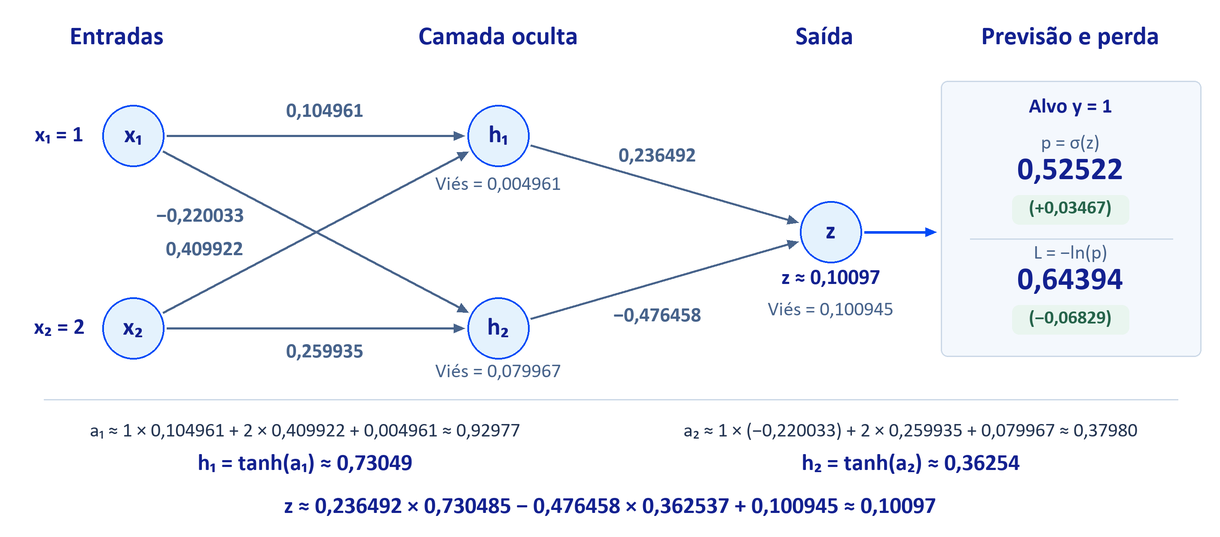

In [ ]:
taxa = 0.1
parametros_novos = tuple(
    parametro - taxa * gradiente
    for parametro, gradiente in zip(parametros, gradientes_np)
)
_, _, z_novo, p_novo = propagacao_numpy(X, parametros_novos)



In [ ]:
# Um modelo novo parte sempre dos pesos da ida, inclusive ao reexecutar a célula.
modelo_atualizado = criar_modelo(parametros)
sgd = keras.optimizers.SGD(learning_rate=taxa)
sgd.apply_gradients(zip(gradientes_keras, modelo_atualizado.trainable_variables))
z_novo_keras = modelo_atualizado(X_tf)
perda_depois_keras = bce(y_tf, z_novo_keras)
perda_depois_numpy = perda_numpy(y, z_novo)



In [ ]:
# A taxa armazenada pelo otimizador pode ser arredondada ao dtype interno.
for parametro_numpy, parametro_keras in zip(parametros_novos, modelo_atualizado.get_weights()):
    np.testing.assert_allclose(parametro_numpy, parametro_keras, atol=1e-8)
np.testing.assert_allclose(perda_depois_numpy, perda_depois_keras.numpy(), atol=1e-8)



In [ ]:
print(f"Probabilidade {p.item():.5f} → {p_novo.item():.5f}")
print(f"Perda {perda_antes_numpy:.5f} → {perda_depois_numpy:.5f}")

## 04 · Um exemplo ou um lote

Com `batch_size` igual a 1, cada exemplo gera um passo. Com $n$ exemplos no lote, fazemos a média das perdas e um passo usando o gradiente médio.

$$
L_{\mathrm{lote}}=\frac{1}{n}\sum_{k=1}^n L_k,\qquad
\nabla L_{\mathrm{lote}}=\frac{1}{n}\sum_{k=1}^n \nabla L_k.
$$

As duas maneiras de calcular a média usam o mesmo estado inicial da rede. Vamos conferir a igualdade com duas observações. A primeira é a do slide. A segunda é sintética e tem alvo 0.

Na GPU, o tamanho do lote afeta o espaço ocupado pelas ativações. O treino também guarda parâmetros, gradientes e, quando aplicável, o estado do otimizador.

In [ ]:
X_lote = np.array([[1.0, 2.0], [2.0, 1.0]])
y_lote = np.array([[1.0], [0.0]])



In [ ]:
gradientes_lote = gradientes_numpy(X_lote, y_lote, parametros)
gradientes_individuais = [
    gradientes_numpy(X_lote[i:i + 1], y_lote[i:i + 1], parametros)
    for i in range(len(X_lote))
]



In [ ]:
for do_lote, por_parametro in zip(gradientes_lote, zip(*gradientes_individuais)):
    media = np.mean(por_parametro, axis=0)
    np.testing.assert_allclose(do_lote, media, atol=1e-12)



In [ ]:
print("Gradiente de w11 calculado no lote", gradientes_lote[0][0, 0])
print("A média dos gradientes individuais coincide com o gradiente do lote.")